In [3]:
import os,re
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import matplotlib.pyplot as plt
from scipy.stats import mode
from tqdm.auto import tqdm
import warnings
warnings.simplefilter("ignore")
def split_umap(adata, split_by, ncol=3, nrow=None, **kwargs):
    categories = adata.obs[split_by].cat.categories
    if nrow is None:
        nrow = int(np.ceil(len(categories) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(5*ncol, 5*nrow))
    axs = axs.flatten()
    for i, cat in enumerate(categories):
        ax = axs[i]
        sc.pl.umap(adata[adata.obs[split_by] == cat], ax=ax, show=False, title=cat, **kwargs)
    plt.tight_layout()

In [4]:
# Read the .h5ad file containing the single-cell RNA-seq data
adata = sc.read_h5ad("nRNA_keep3Animal_1stQC_regMito_cca.h5ad")
adata

AnnData object with n_obs × n_vars = 312321 × 20966
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'doublet_score', 'percent.mt', 'Exprlevel', 'SampleName', 'BrainRegion', 'Animal', 'Source', 'Date', 'Submitter', 'CNGB_No.', 'Matrix_Directory', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.1', 'seurat_clusters'
    var: 'names'
    obsm: 'X_integrated.dr', 'X_pca', 'X_umap'

In [5]:
### Build Graph and Embedding
sc.pp.neighbors(adata, use_rep="X_integrated.dr")
sc.tl.louvain(adata, resolution = 1)
sc.tl.umap(adata)

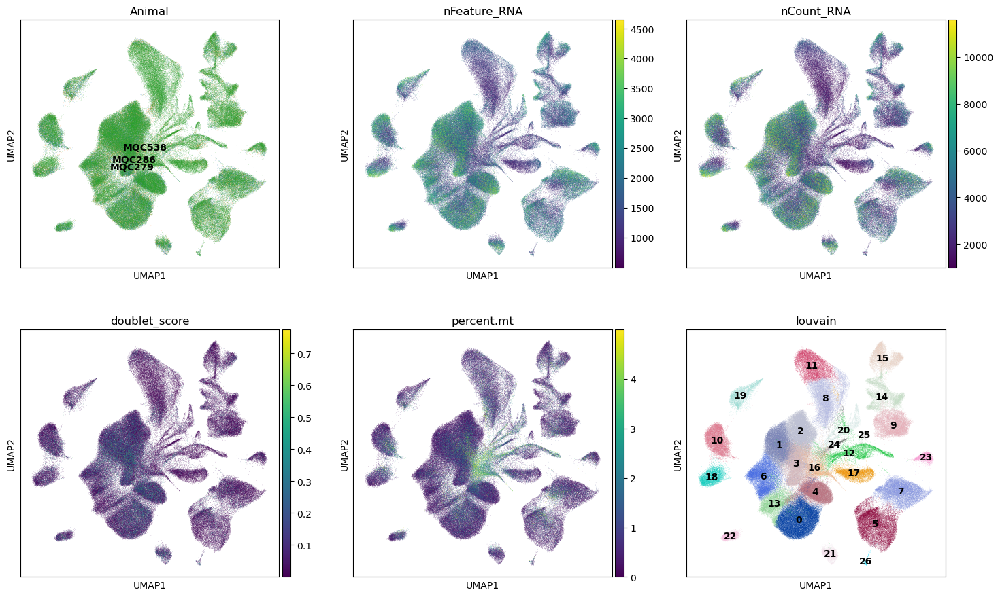

In [7]:
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata, color = ["Animal","nFeature_RNA","nCount_RNA","doublet_score", "percent.mt","louvain"],ncols=3,legend_loc = "on data")

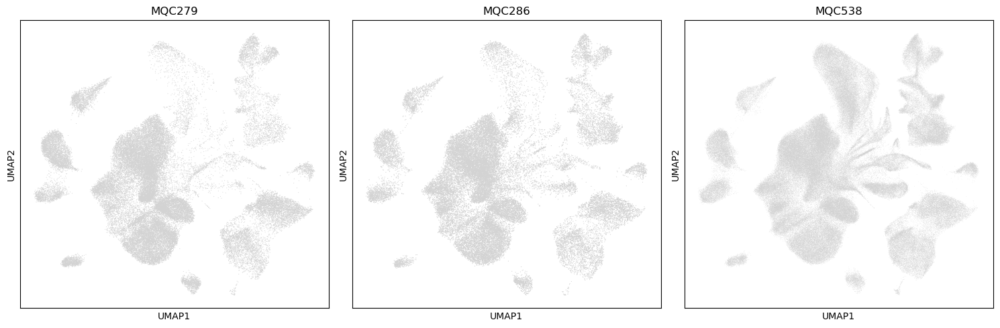

In [8]:
split_umap(adata, "Animal", ncol=3)

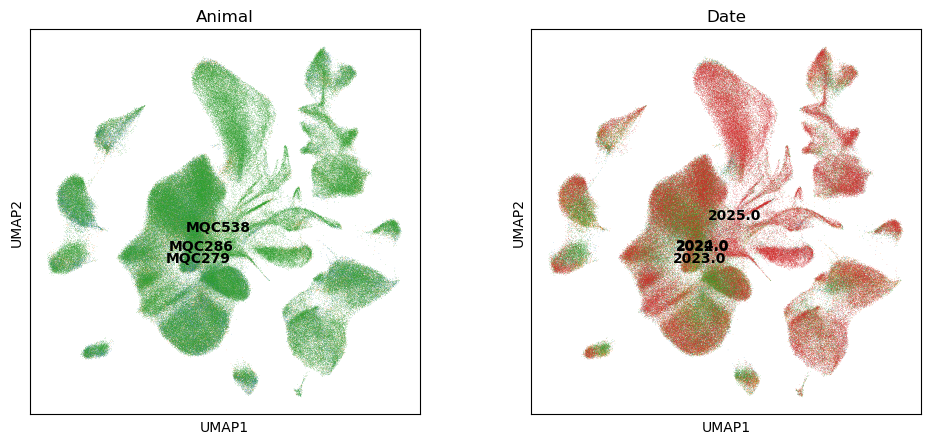

In [9]:
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata, color = ["Animal","Date"],ncols=3,legend_loc = "on data")

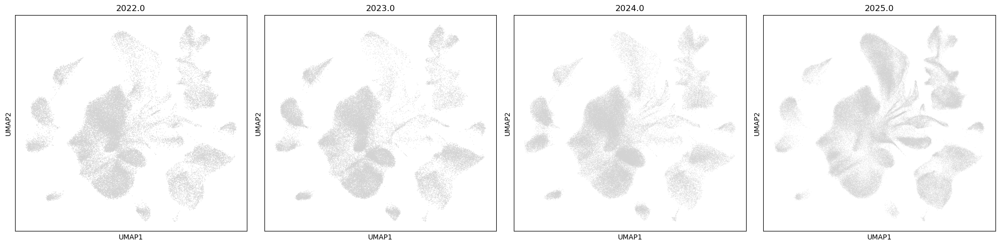

In [10]:
split_umap(adata, "Date", ncol=4)

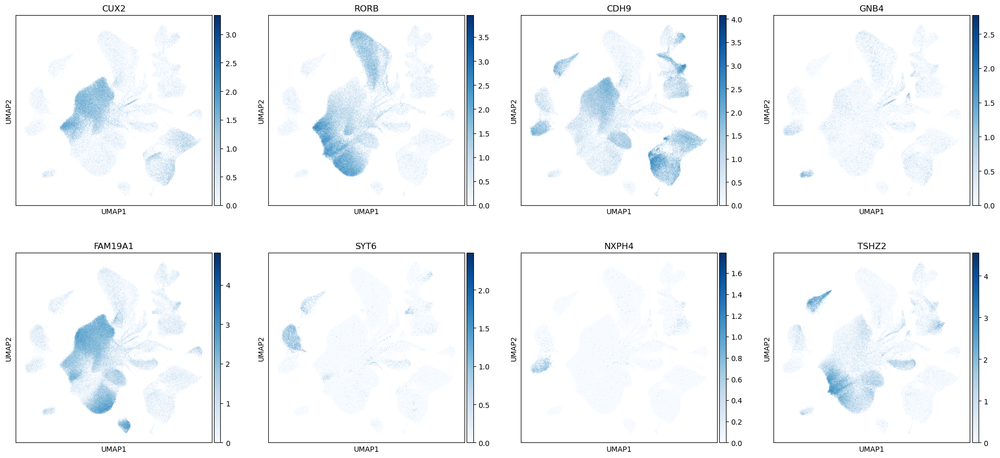

In [11]:
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata, color = ['CUX2','RORB','CDH9','GNB4','FAM19A1','SYT6','NXPH4','TSHZ2'],legend_loc = "on data", cmap= "Blues", size = 1)

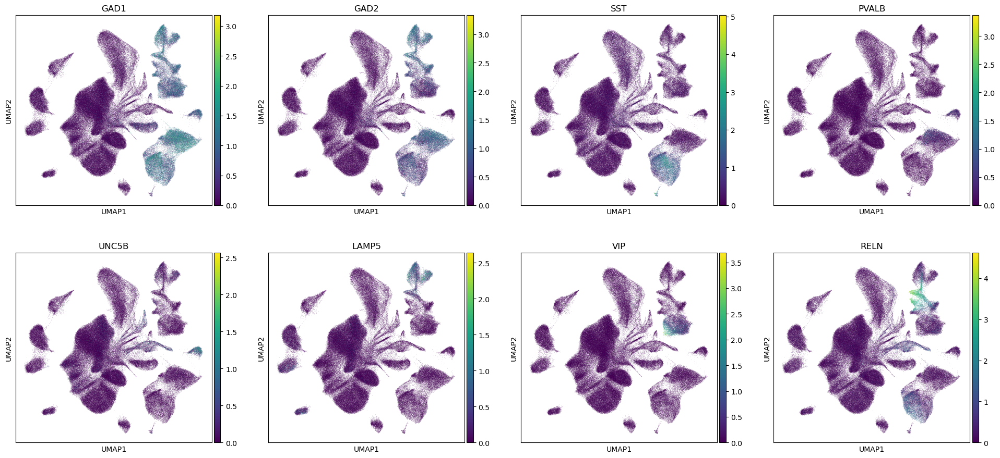

In [12]:
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata, color = ['GAD1','GAD2','SST','PVALB','UNC5B','LAMP5','VIP','RELN'],legend_loc = "on data")

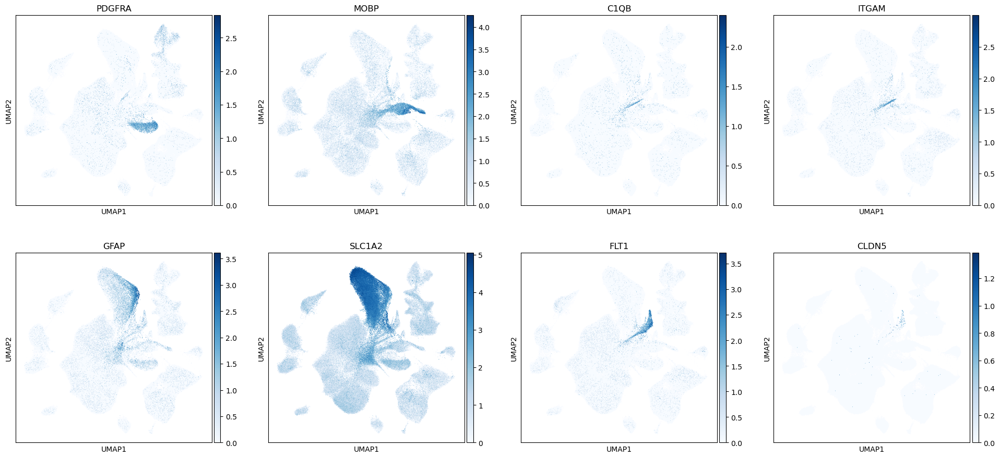

In [13]:
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata, color = ['PDGFRA','MOBP','C1QB',"ITGAM","GFAP",'SLC1A2','FLT1',"CLDN5"],legend_loc = "on data", cmap= "Blues", size = 2)

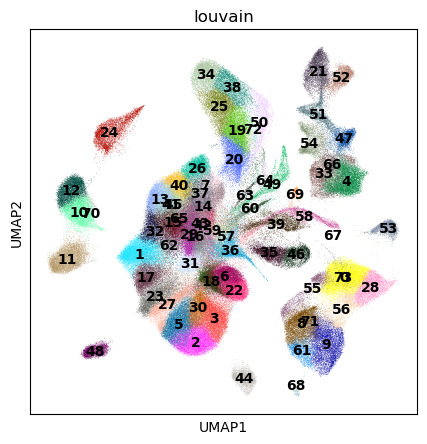

In [24]:
### set a high-resolution clustering for defining cell states.
sc.tl.louvain(adata, resolution = 5)
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata, color = ['louvain'],legend_loc = "on data")

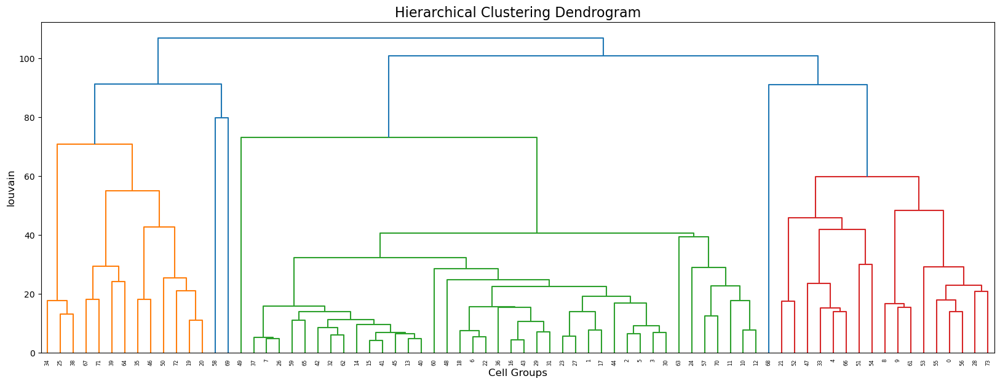

In [53]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

data = pd.DataFrame(adata.obsm['X_integrated.dr'], index=adata.obs.index)
cell_groups = adata.obs['louvain']
data = data.groupby(cell_groups).mean()
Z = linkage(data, method='ward')

plt.figure(figsize=(20, 7))
dendrogram(Z, labels=data.index, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram', fontsize=16)
plt.xlabel('Cell Groups', fontsize=12)
plt.ylabel('louvain', fontsize=12)
plt.show()

### Annotate Major Cell Classes

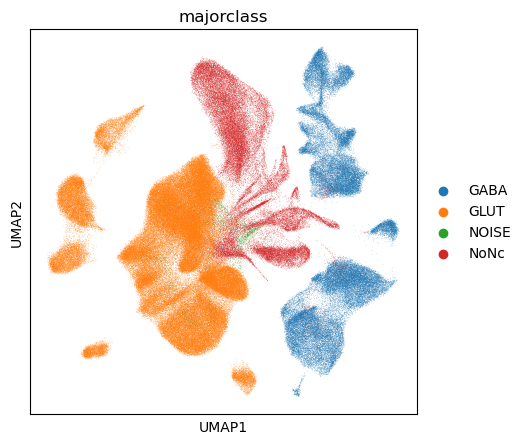

In [78]:
AnnotList = {
    'GLUT': [],
    'GABA': ["68","21","52","47","33","4","66","51","54","8","9","61","55","0","56","28","73","53"],
    'NoNc': ["34","25","38","67","71","39","64","35","46","50","72","19","20","58","69","49","60","63","36"],
    'NOISE' : ["57"]
}
mapping_dict = {vi: k  for k, v in AnnotList.items() for vi in v}
adata.obs['majorclass'] = adata.obs['louvain'].map(mapping_dict).fillna('GLUT')
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata, color=["majorclass"])

### Annotate Glutamatergic Neuron Subclasses

In [51]:
adata_ex = adata[adata.obs["majorclass"] == "GLUT"].copy()

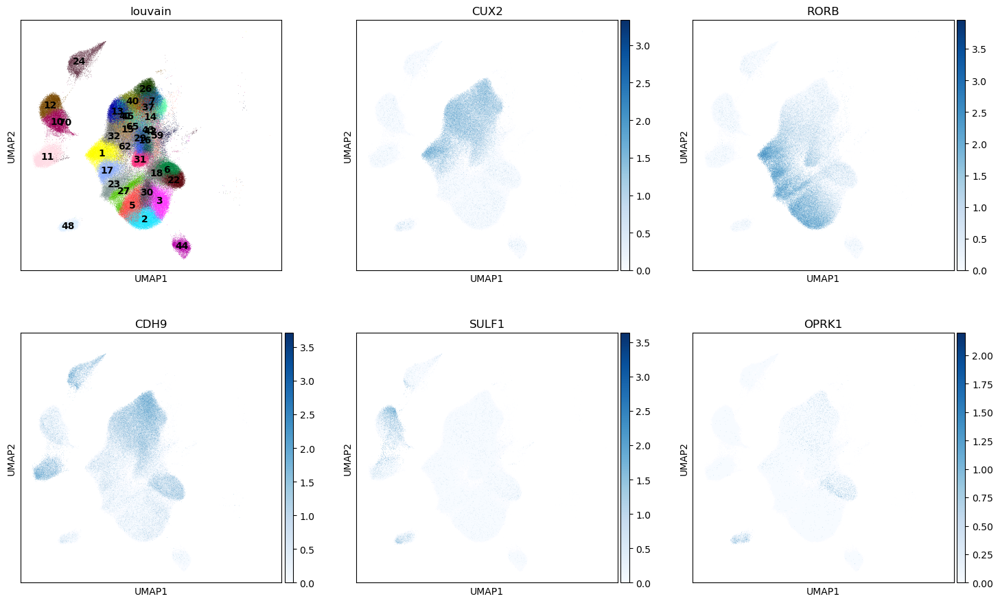

In [55]:
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_ex, color = ['louvain','CUX2','RORB','CDH9',"SULF1","OPRK1"],legend_loc = "on data",ncols= 3, cmap= 'Blues')

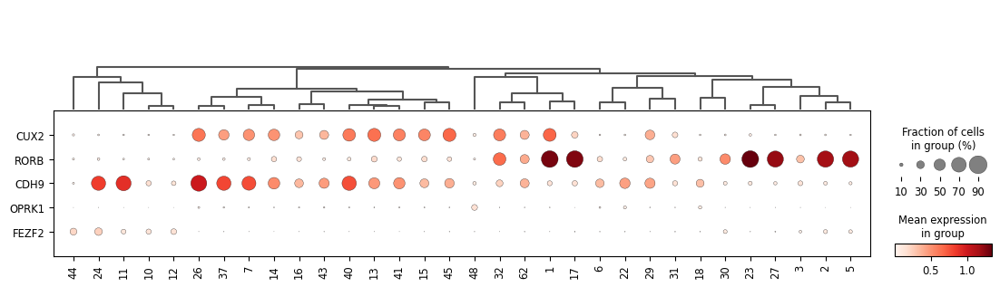

In [69]:
with plt.rc_context({"figure.figsize": (10, 5)}):
    sc.pl.dotplot(adata_ex[~adata_ex.obs.louvain.isin(["70","65","42","59"]),:],["CUX2","RORB",'CDH9',"OPRK1","FEZF2"], groupby='louvain', dendrogram= True, swap_axes= True)

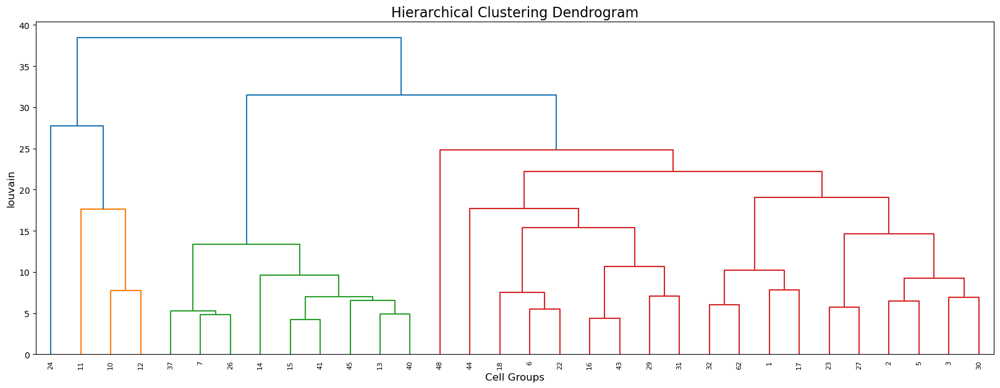

In [68]:
data = pd.DataFrame(adata_ex.obsm['X_integrated.dr'], index=adata_ex.obs.index)
cell_groups = adata_ex.obs['louvain']
data = data.groupby(cell_groups).mean()
data = data.drop(index = ["70","65","42","59"])
Z = linkage(data, method='ward')

plt.figure(figsize=(20, 7))
dendrogram(Z, labels=data.index, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram', fontsize=16)
plt.xlabel('Cell Groups', fontsize=12)
plt.ylabel('louvain', fontsize=12)
plt.show()

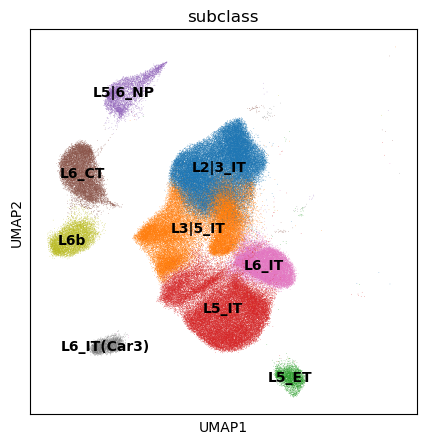

In [72]:
AnnotList = {
    'L2|3_IT': ["37","7","26","14","15","41","45","13","40"],
    'L3|5_IT': [],
    'L5_IT': ["23","27","2","5","3","30"],
    'L6_IT': ["6","22","18"],
    'L6_IT(Car3)': ["48"],
    'L5|6_NP': ["24"],
    'L6_CT': ["12","10","70"],
    'L6b': ["11"],
    'L5_ET': ["44"],
    'NOISE' : ["70","65","42","59"]
}
mapping_dict = {vi: k  for k, v in AnnotList.items() for vi in v}
adata_ex.obs['subclass'] = adata_ex.obs['louvain'].map(mapping_dict).fillna('L3|5_IT')
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_ex[adata_ex.obs["subclass"] != "NOISE"], color=["subclass"],  legend_loc = "on data")

In [73]:
adata_ex.obs.to_csv("GLUT_1stAnnot.csv")

### Annotate GABAergic Neuron Subclasse

In [79]:
adata_in = adata[adata.obs["majorclass"] == "GABA"].copy()

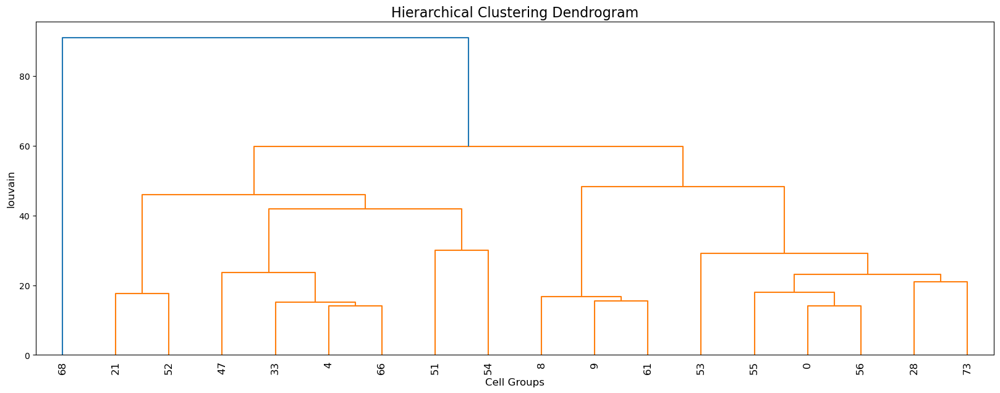

In [81]:
data = pd.DataFrame(adata_in.obsm['X_integrated.dr'], index=adata_in.obs.index)
cell_groups = adata_in.obs['louvain']
data = data.groupby(cell_groups).mean()
Z = linkage(data, method='ward')

plt.figure(figsize=(20, 7))
dendrogram(Z, labels=data.index, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram', fontsize=16)
plt.xlabel('Cell Groups', fontsize=12)
plt.ylabel('louvain', fontsize=12)
plt.show()

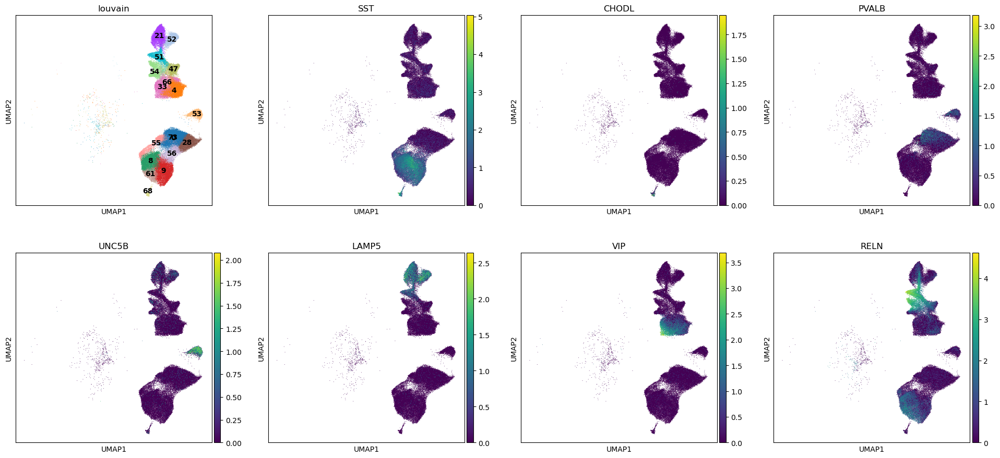

In [82]:
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_in, color = ['louvain','SST','CHODL','PVALB','UNC5B','LAMP5','VIP','RELN'],legend_loc = "on data",)

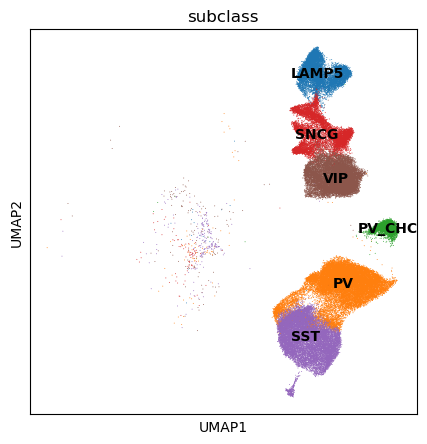

In [84]:
AnnotList = {
    'SST': ["68","61","8","9"],
    'PV': ["55","0","56","28","73"],
    'PV_CHC': ["53"],
    'VIP': ["4","33","66"],
    'SNCG': [],
    'LAMP5': ["21","52"]
}
mapping_dict = {vi: k  for k, v in AnnotList.items() for vi in v}
adata_in.obs['subclass'] = adata_in.obs['louvain'].map(mapping_dict).fillna('SNCG')
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_in, color=["subclass"],  legend_loc = "on data")

In [85]:
adata_in.obs.to_csv("GABA_1stAnnot.csv")

### Annotate None-Neuron Subclasses

In [115]:
adata_nc = adata[adata.obs["majorclass"] == "NoNc"].copy()

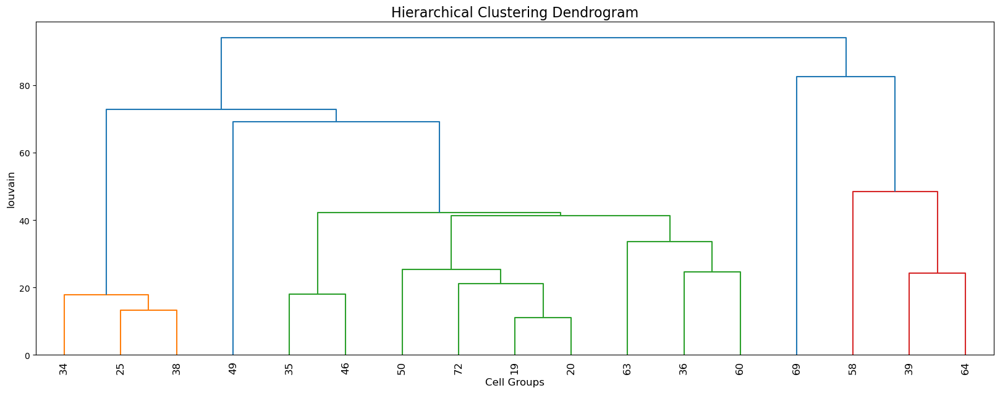

In [119]:
data = pd.DataFrame(adata_nc.obsm['X_integrated.dr'], index=adata_nc.obs.index)
cell_groups = adata_nc.obs['louvain']
data = data.groupby(cell_groups).mean()
data = data.drop(index = ["71","67"])

Z = linkage(data, method='ward')

plt.figure(figsize=(20, 7))
dendrogram(Z, labels=data.index, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram', fontsize=16)
plt.xlabel('Cell Groups', fontsize=12)
plt.ylabel('louvain', fontsize=12)
plt.show()

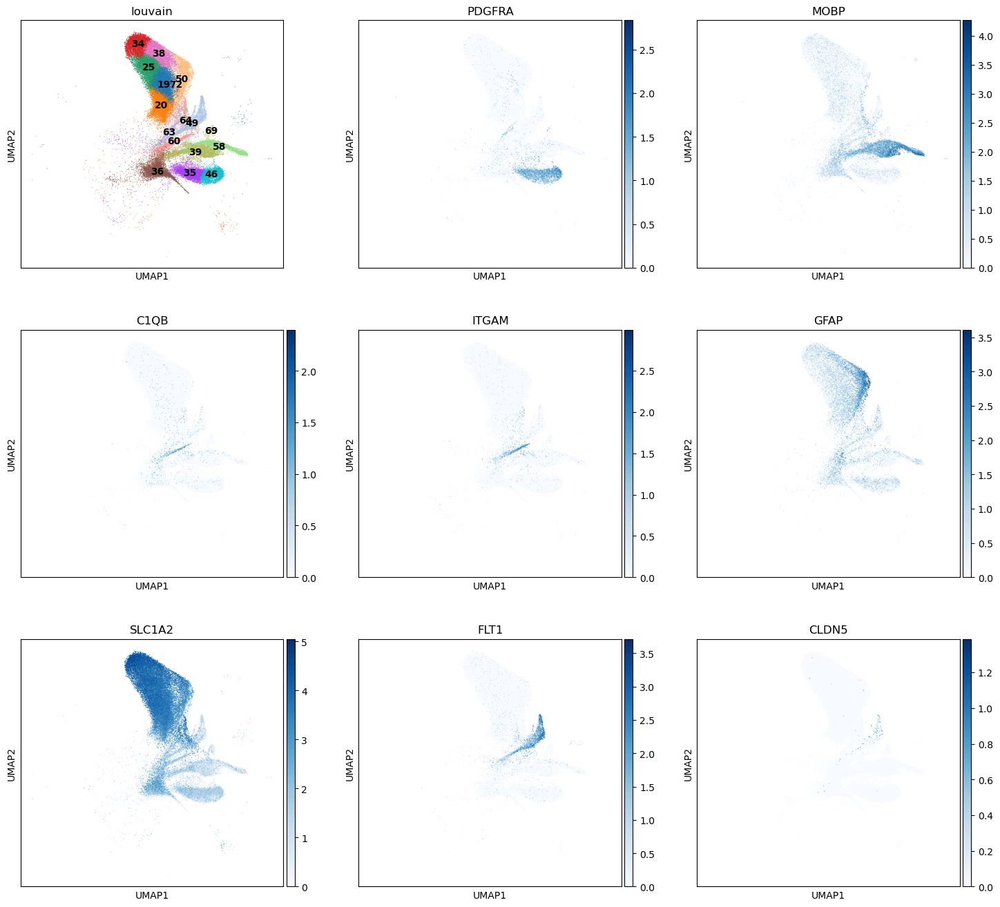

In [118]:
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_nc[~adata_nc.obs.louvain.isin(["71","67"]),:], color = ["louvain",'PDGFRA','MOBP','C1QB',"ITGAM","GFAP",'SLC1A2','FLT1',"CLDN5"],legend_loc = "on data", cmap= "Blues",ncols = 3, size = 2)

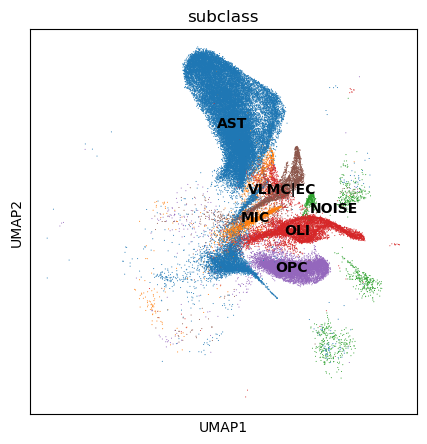

In [275]:
AnnotList = {
    'AST': [],
    'OPC': ["35","46"],
    'OLI': ["58","39","64"],
    'MIC': ["60"],
    'VLMC|EC': ["49"],
    'NOISE': ["71","67","69"]
}

mapping_dict = {vi: k  for k, v in AnnotList.items() for vi in v}
adata_nc.obs['subclass'] = adata_nc.obs['louvain'].map(mapping_dict).fillna('AST')
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_nc, color=["subclass"],  legend_loc = "on data")

In [276]:
adata_nc.obs.to_csv("NoNc_1stAnnot.csv")

### Combine Annotation

In [277]:
combine_barcodes = pd.concat([adata_ex.obs, adata_in.obs, adata_nc.obs], ignore_index=False)
adata_clean = adata[adata.obs_names.isin(combine_barcodes.index),:].copy()
adata_clean.obs = combine_barcodes.reindex(adata_clean.obs_names)
adata_clean = adata_clean[adata_clean.obs['majorclass'] != "NOISE"].copy()
adata_clean = adata_clean[adata_clean.obs[ 'subclass' ] != "NOISE"].copy()

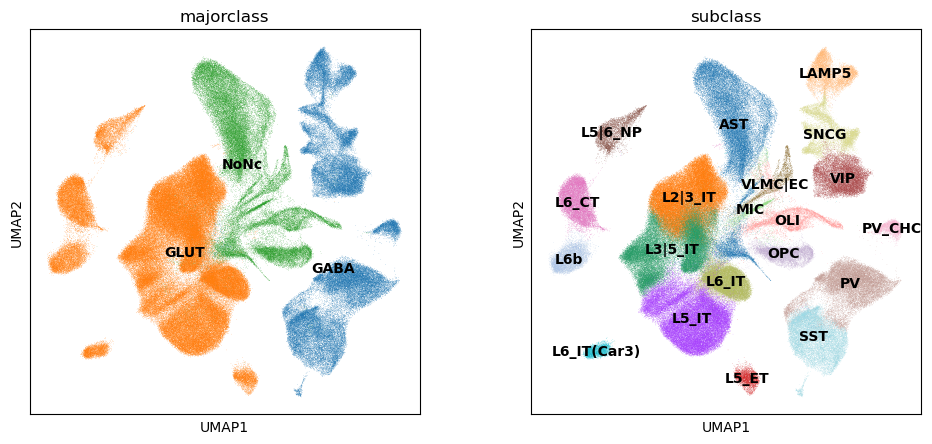

In [279]:
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_clean, color=["majorclass","subclass"],  legend_loc = "on data")

In [280]:
adata_clean.write_h5ad("nRNA_keep3Animal_1stQC_regMito_withAnnot.h5ad")

#### Superclustering for Celltype Identification

In [288]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from joblib import Parallel, delayed
from scipy.stats import gmean
import scanpy as sc
import anndata as ad
np.random.seed(None)

def _evaluate_f1(X_train, X_test, y_train, y_test):
    rf = RandomForestClassifier(n_estimators=500, random_state=42, class_weight='balanced')
    rf.fit(X_train, y_train)
    rf_report = classification_report(y_test, rf.predict(X_test), output_dict=True)
    return pd.DataFrame(rf_report).transpose()['f1-score'].min()

def _sample_evaluate(clean_adata, N = 100):
    sampled_cells = []
    for cluster in clean_adata.obs['louvain_clusters'].unique():
        cells_in_cluster = clean_adata[clean_adata.obs['louvain_clusters'] == cluster].copy()
        sampled_cells.append(cells_in_cluster[np.random.choice(cells_in_cluster.n_obs, min(cells_in_cluster.n_obs, N), replace=False)])

    sampled_adata = ad.concat(sampled_cells, index_unique="_", join="outer")
    X_train, X_test, y_train, y_test = train_test_split(
        sampled_adata.obsm["X_pca"], sampled_adata.obs['louvain_clusters'], test_size=0.3, random_state=42
    )
    smote = SMOTE(random_state=42)
    if len(np.unique(y_train)) > 1:
        X_train, y_train = smote.fit_resample(X_train, y_train)
    
    return _evaluate_f1(X_train, X_test, y_train, y_test)

def SuperClusterValidator(adata, cut_score = 0.6, **kwargs):
    previous_result = None
    cluster_counts = 0
    for res in np.arange(0.1, 8.1, 0.1):
        sc.tl.louvain(adata, resolution=res, key_added='louvain_clusters')
        valid_clusters = adata.obs['louvain_clusters'].value_counts()
        valid_clusters = valid_clusters[valid_clusters > 30].index

        if len(valid_clusters) <= cluster_counts: 
            continue
        else:
            cluster_counts = len(valid_clusters)
        
        clean_adata = adata[adata.obs['louvain_clusters'].isin(valid_clusters)].copy()
        avg_min_F1 = np.mean(Parallel(n_jobs = 20, prefer="processes")(delayed(_sample_evaluate)(clean_adata) for _ in range(100)))
        if avg_min_F1 > cut_score:
            previous_result = clean_adata.obs.copy()
        else:
            return previous_result if previous_result is not None else clean_adata.obs.copy()

In [213]:
adata_clean = sc.read_h5ad("nRNA_keep3Animal_1stQC_regMito_withAnnot.h5ad")
adata_clean

AnnData object with n_obs × n_vars = 301359 × 20966
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'doublet_score', 'percent.mt', 'Exprlevel', 'SampleName', 'BrainRegion', 'Animal', 'Source', 'Date', 'Submitter', 'CNGB_No.', 'Matrix_Directory', 'louvain', 'majorclass', 'subclass', 'Area', 'cellcluster'
    var: 'names'
    uns: 'Animal_colors', 'Date_colors', 'cellcluster_colors', 'louvain', 'louvain_colors', 'majorclass_colors', 'neighbors', 'seurat_clusters_colors', 'subclass_colors', 'umap'
    obsm: 'X_integrated.dr', 'X_pca', 'X_umap'
    obsp: 'connectivities', 'distances'

In [ ]:
rslt_list = []
for i in adata_clean.obs["subclass"].unique():
    adata_temp = adata_clean[adata_clean.obs['subclass'] == i].copy()
    tmpt_obs = SuperClusterValidator(adata=adata_temp)
    tmpt_obs['louvain_clusters'] = tmpt_obs['louvain_clusters'].astype(str).apply(lambda x: str(x).zfill(2))
    tmpt_obs['cellcluster'] = tmpt_obs['subclass'].astype(str) + '.' + tmpt_obs['louvain_clusters'].astype(str)
    rslt_list.append(tmpt_obs)

new_obs = pd.concat(rslt_list, ignore_index=False).reindex(adata_clean.obs_names)
del new_obs["louvain_clusters"]

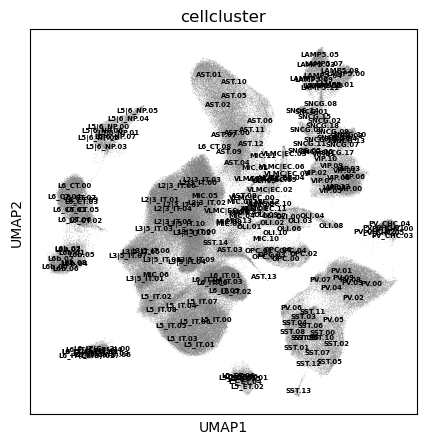

In [292]:
adata_clean.obs = new_obs
adata_clean = adata_clean[adata_clean.obs['cellcluster'].notna(), :]
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_clean, color=["cellcluster"],  legend_loc = "on data", legend_fontsize= 5)

In [293]:
adata_clean.write_h5ad("nRNA_keep3Animal_1stQC_regMito_withAnnot.h5ad")
adata_clean.obs.to_csv("nRNA_keep3Animal_1stQC_regMito_withAnnot.obs.csv")

### Merge Clusters with Insignificant Differential Gene Scores

In [294]:
from scipy.spatial.distance import cdist
from collections import Counter
def _deScore(adata, clust):
    rank_dt = sc.get.rank_genes_groups_df(adata, group=clust)
    rank_dt['log_pvals'] = -np.log10(rank_dt['pvals_adj'])
    rank_dt['de_score'] = np.abs(rank_dt['logfoldchanges']) * np.minimum(20, rank_dt['log_pvals'])
    sum_descore = rank_dt[rank_dt['pvals_adj'] < 0.05]['de_score'].sum()
    return sum_descore

def get_current_merge(adata, ident, th = 100):
    sc.tl.rank_genes_groups(adata, ident, method='wilcoxon')
    score_dict = {clust: _deScore(adata, clust) for clust in adata.obs[ident].unique()}
    need_to_merge = [key for key, value in score_dict.items() if value < th]
    return need_to_merge
    
def find_nearest_cluster(x_pca, labels, val):
    unique_labels = labels.unique()
    cluster_centers = {clust: x_pca[labels == clust,:].mean(axis=0) for clust in unique_labels}
    
    dist_mtx = pd.DataFrame(
        cdist(np.vstack(cluster_centers.values()), np.vstack(cluster_centers.values()), metric='euclidean'), 
        index=unique_labels, columns=unique_labels
    )
    nearest_cluster = dist_mtx.loc[val].drop(val).idxmin()
    return nearest_cluster

In [248]:
adata_clean = sc.read_h5ad("nRNA_keep3Animal_1stQC_regMito_withAnnot.h5ad")

In [ ]:
mito_genes = np.asarray(["ND6","COX3","COX1","ND5","ND4","ND2","ND4L","ATP8","CYTB","COX2","ND3","ATP6","ND1"])
for subclass in adata_clean.obs.subclass.unique():
    print(f"Iteration: {subclass}")
    iteration_counter = 0
    while True:
        adata_ = adata_clean[adata_clean.obs.subclass == subclass, ~np.isin(adata_clean.var_names, mito_genes)].copy()
        need_to_merge = get_current_merge(adata_, "cellcluster", 1000)
        if len(need_to_merge) > 0:
            current_merge = np.random.choice(need_to_merge)
        else:
            print(f"No need to merge for subclass {subclass}. Breaking the loop.")
            break
            
        print(f"Merging Iteration: {iteration_counter}")
        x_pca = adata_.obsm['X_pca']
        labels = adata_.obs["cellcluster"].values
        nearest_cluster = find_nearest_cluster(x_pca,labels,current_merge)

        mapping_dict = {current_merge:nearest_cluster}
        adata_clean.obs['cellcluster'] = adata_clean.obs['cellcluster'].replace(mapping_dict)

In [326]:
### Recode Cell type identity
adata_clean.obs['subclass_group'] = adata_clean.obs.groupby('subclass')['cellcluster'].transform(lambda x: pd.factorize(x)[0] + 1)
adata_clean.obs['subclass_group'] = adata_clean.obs['subclass_group'].astype(str).apply(lambda x: str(x).zfill(2))
adata_clean.obs['cellcluster'] = adata_clean.obs['subclass'].astype(str) + '.' + adata_clean.obs['subclass_group'].astype(str)

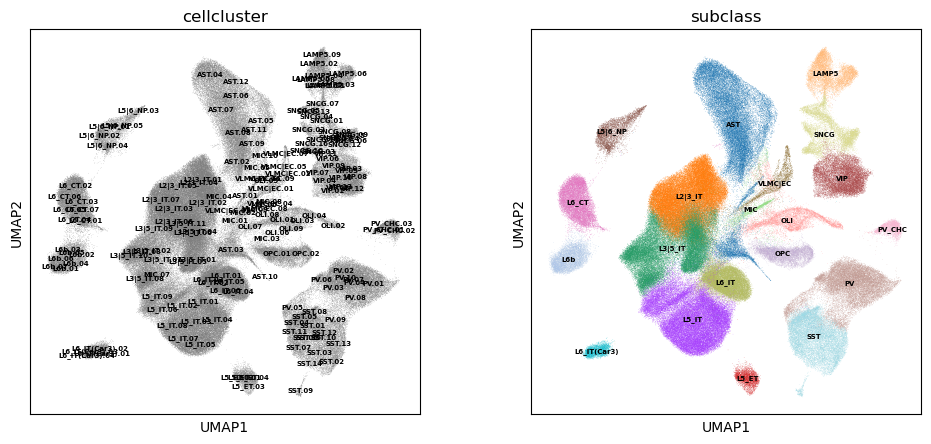

169

In [334]:
adata_clean = adata_clean[adata_clean.obs['cellcluster'].notna(), :]
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_clean, color=["cellcluster","subclass"],  legend_loc = "on data", legend_fontsize= 5)
len(adata_clean.obs["cellcluster"].unique())

In [347]:
adata_clean.obs['UMAP_1'], adata_clean.obs['UMAP_2'] = adata_clean.obsm['X_umap'][:,0], adata_clean.obsm['X_umap'][:,1]
adata_clean.obs.to_csv("nRNA_keep3Animal_finalAnnot.obs.csv")
adata_clean.write_h5ad("nRNA_keep3Animal_finalAnnot.h5ad")

### Generate Global Confusion Heatmap for Cell Classification

In [349]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from imblearn.over_sampling import SMOTE
from joblib import Parallel, delayed
from scipy.stats import gmean
import scanpy as sc
import anndata as ad
np.random.seed(None)

def _confusion_matrix(X_train, X_test, y_train, y_test, label_order = None):
    rf = RandomForestClassifier(n_estimators=500, random_state=42, class_weight='balanced')
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels= label_order)
    cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True)
    return cm_normalized

def _sample_data(adata, N = 100, **kwargs):
    sampled_cells = []
    for cluster in adata.obs['cellcluster'].unique():
        cells_in_cluster = adata[adata.obs['cellcluster'] == cluster].copy()
        sampled_cells.append(cells_in_cluster[np.random.choice(cells_in_cluster.n_obs, min(cells_in_cluster.n_obs, N), replace=False)])

    sampled_adata = ad.concat(sampled_cells, index_unique="_", join="outer")
    X_train, X_test, y_train, y_test = train_test_split(
        sampled_adata.obsm["X_pca"], sampled_adata.obs['cellcluster'], test_size=0.3, random_state=42
    )
    smote = SMOTE(random_state=42)
    if len(np.unique(y_train)) > 1:
        X_train, y_train = smote.fit_resample(X_train, y_train)
    return _confusion_matrix(X_train, X_test, y_train, y_test, **kwargs)

In [ ]:
adata_clean = sc.read_h5ad("nRNA_keep3Animal_finalAnnot.h5ad")
all_classes = np.unique(adata_clean.obs['cellcluster'])
cm_list = Parallel(n_jobs = 20, prefer="processes")(delayed(_sample_data)(adata_clean, label_order = all_classes) for _ in tqdm(range(100)))

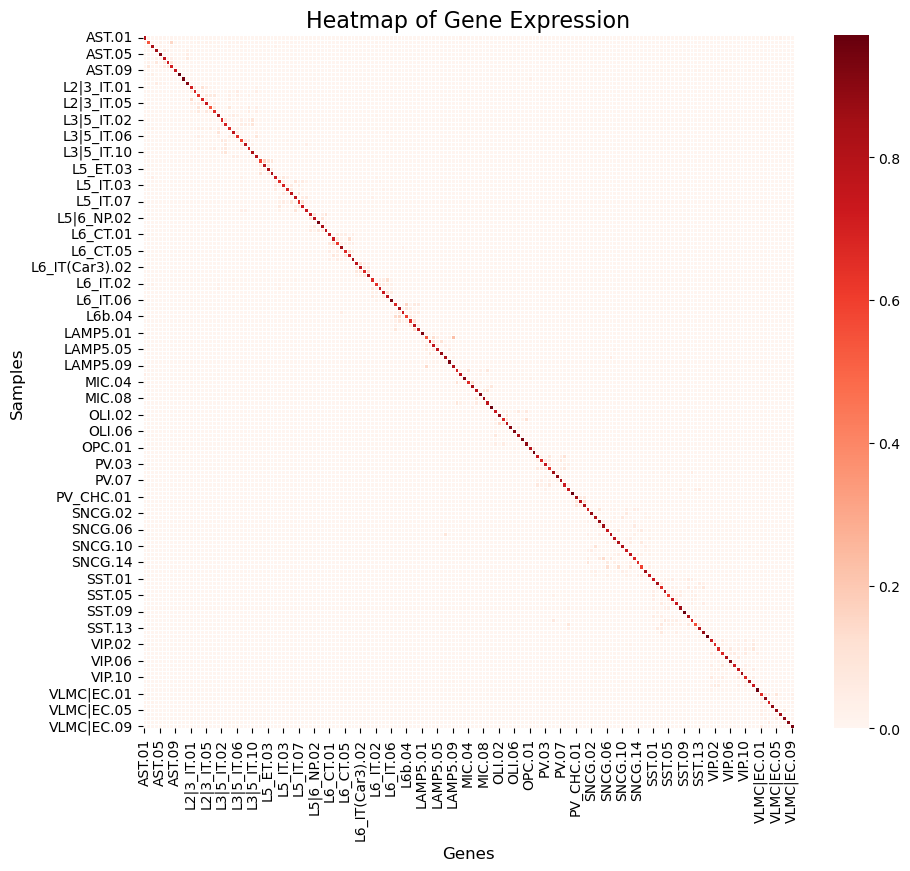

In [351]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt_dt = pd.DataFrame(np.mean(cm_list, axis = 0), index= all_classes, columns=all_classes)
plt.figure(figsize=(10.5, 9))
sns.heatmap(plt_dt, cmap='Reds', annot= False, fmt='.2f', linewidths=0.5)

plt.title('Heatmap of Gene Expression', fontsize=16)
plt.xlabel('Genes', fontsize=12)
plt.ylabel('Samples', fontsize=12)

plt.show()

In [352]:
plt_dt.to_csv("100times_confusion_matrix.tsv",sep = "\t")